**Import Library & Upload Data**

In [10]:
import re
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

print("=== TAHAP 1: UNGGAH DATA KUESIONER ===")
print("Silakan pilih file Excel (.xlsx) hasil unduhan dari spreadsheet:")
unggah = files.upload()
nama_file = list(unggah.keys())[0]
print(f"\n[BERHASIL] File '{nama_file}' siap diproses.")

=== TAHAP 1: UNGGAH DATA KUESIONER ===
Silakan pilih file Excel (.xlsx) hasil unduhan dari spreadsheet:


Saving data mahasiswa.xlsx to data mahasiswa (1).xlsx

[BERHASIL] File 'data mahasiswa (1).xlsx' siap diproses.


**Membaca & Menyiapkan Data**

In [11]:
print("=== TAHAP 2: FILTER DATA KELAS 3 TI A & PEMBERSIHAN ===")
df_mentah = pd.read_excel(nama_file)

# 1. Ambil hanya data responden dari kelas 3 TI A
df_3tia = df_mentah[df_mentah['Kelas'].astype(str).str.strip() == '3 TI A'].copy()

# 2. Ambil hanya kolom pernyataan skala Likert (ditandai dengan kurung siku '[')
# Langkah ini otomatis melewati kolom demografi dan kolom durasi gadget di tengah
kolom_pernyataan = [kol for kol in df_3tia.columns if '[' in str(kol)]
data_butir = df_3tia[kolom_pernyataan]

# 3. Ubah jawaban teks menjadi skor angka (1 sampai 5)
kamus_skala = {
    "Sangat Tidak Setuju (STS)": 1,
    "Tidak Setuju (TS)": 2,
    "Netral (N)": 3,
    "Setuju (S)": 4,
    "Sangat Setuju (SS)": 5,
}
data_angka = data_butir.replace(kamus_skala).apply(pd.to_numeric, errors="coerce")

# 4. Kelompokkan butir soal berdasarkan nama dimensinya
daftar_dimensi = {}
for kol in data_butir.columns:
    cocok = re.match(r"^(.*?) \[", kol)
    if cocok:
        nama_dim = cocok.group(1).strip()
        daftar_dimensi.setdefault(nama_dim, []).append(kol)

# Tampilkan ringkasan data yang mudah dibaca
print(f"Total seluruh data di file : {len(df_mentah)} responden")
print(f"Data khusus Kelas 3 TI A   : {len(df_3tia)} responden (Data yang diuji)")
print(f"Total butir pernyataan     : {data_butir.shape[1]} butir")
print(f"Data gagal terbaca/kosong  : {int(data_angka.isna().sum().sum())} sel (Harus 0)")

print("\nPembagian Dimensi Kuesioner:")
for idx, (nama_dim, list_soal) in enumerate(daftar_dimensi.items(), 1):
    print(f"  {idx}. {nama_dim} ({len(list_soal)} butir soal)")

=== TAHAP 2: FILTER DATA KELAS 3 TI A & PEMBERSIHAN ===
Total seluruh data di file : 181 responden
Data khusus Kelas 3 TI A   : 39 responden (Data yang diuji)
Total butir pernyataan     : 29 butir
Data gagal terbaca/kosong  : 0 sel (Harus 0)

Pembagian Dimensi Kuesioner:
  1. Penggunaan AI pada tugas atau projek kuliah (7 butir soal)
  2. Aspek Psikologis penggunaan AI pada tugas atau projek kuliah (7 butir soal)
  3. Kebiasaan penggunaan teknologi digital (6 butir soal)
  4. Prokrastinasi akademik. (4 butir soal)
  5. Rsspon emosional (5 butir soal)


/tmp/ipykernel_2622/3441078382.py:20: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data_angka = data_butir.replace(kamus_skala).apply(pd.to_numeric, errors="coerce")


**Pengujian Validitas, Reliabilitas, dan Visualisasi Grafik**

In [12]:
print("=== TAHAP 3: HASIL UJI VALIDITAS, RELIABILITAS & DESKRIPTIF ===")

# Hitung batas r-tabel (alpha = 0,05 uji dua sisi, df = n - 2)
n = len(data_angka)
df_bebas = n - 2
t_kritis = stats.t.ppf(0.975, df_bebas)
r_tabel = t_kritis / np.sqrt(df_bebas + t_kritis**2)

print(f"Jumlah Responden (n) : {n}")
print(f"Derajat Bebas (df)   : {df_bebas}")
print(f"Nilai r-tabel (5%)   : {r_tabel:.3f} (Butir dinyatakan VALID jika r-hitung > {r_tabel:.3f})\n")

# Fungsi hitung Cronbach's Alpha
def hitung_cronbach_alpha(x):
    k = x.shape[1]
    if k < 2:
        return 0.0
    return (k / (k - 1)) * (1 - x.var(ddof=1).sum() / x.sum(axis=1).var(ddof=1))

def status_reliabilitas(nilai_alpha):
    if nilai_alpha >= 0.90:
        return "Sangat Baik (Reliabel)"
    elif nilai_alpha >= 0.80:
        return "Baik (Reliabel)"
    elif nilai_alpha >= 0.70:
        return "Cukup (Reliabel)"
    else:
        return "Tidak Reliabel (< 0,70)"

hasil_validitas = []
hasil_reliabilitas = []
hasil_alpha_dihapus = []
hasil_deskriptif = []

for nama_dim, list_soal in daftar_dimensi.items():
    skor_dimensi = data_angka[list_soal]
    skor_total = skor_dimensi.sum(axis=1)

    # A. Hitung Validitas per Butir
    for i, kol in enumerate(list_soal, 1):
        r_hitung, p_val = stats.pearsonr(skor_dimensi[kol], skor_total)
        r_koreksi, _ = stats.pearsonr(skor_dimensi[kol], skor_total - skor_dimensi[kol])
        status = "VALID" if r_hitung > r_tabel else "TIDAK VALID"

        hasil_validitas.append({
            "Dimensi": nama_dim,
            "Kode Butir": f"B{i}",
            "r-hitung": round(r_hitung, 3),
            "r-tabel": round(r_tabel, 3),
            "Corrected r": round(r_koreksi, 3),
            "p-value": round(p_val, 4),
            "Keputusan": status
        })

    # B. Hitung Reliabilitas per Dimensi
    alpha = hitung_cronbach_alpha(skor_dimensi)
    hasil_reliabilitas.append({
        "Dimensi": nama_dim,
        "Jumlah Butir": len(list_soal),
        "Cronbach's Alpha": round(alpha, 3),
        "Kategori Reliabilitas": status_reliabilitas(alpha)
    })

    # C. Hitung Alpha jika butir dihapus
    for i, kol in enumerate(list_soal, 1):
        if len(list_soal) > 2:
            alpha_tanpa_butir = hitung_cronbach_alpha(skor_dimensi.drop(columns=kol))
            hasil_alpha_dihapus.append({
                "Dimensi": nama_dim,
                "Kode Butir": f"B{i}",
                "Alpha Jika Dihapus": round(alpha_tanpa_butir, 3)
            })

    # D. Hitung Statistik Deskriptif (Mean, Standar Deviasi, Skewness, Kurtosis)
    hasil_deskriptif.append({
        "Dimensi": nama_dim,
        "Rata-rata Skor Total": round(skor_total.mean(), 3),
        "Standar Deviasi": round(skor_total.std(), 3),
        "Skewness (Kemencengan)": round(skor_total.skew(), 3),
        "Kurtosis (Keruncingan)": round(skor_total.kurtosis(), 3)
    })

# Buat Tabel DataFrame agar rapi saat ditampilkan
df_validitas = pd.DataFrame(hasil_validitas)
df_reliabilitas = pd.DataFrame(hasil_reliabilitas)
df_alpha_dihapus = pd.DataFrame(hasil_alpha_dihapus)
df_deskriptif = pd.DataFrame(hasil_deskriptif)

# Gabungkan tabel validitas dengan kolom Alpha Jika Dihapus
tabel_validitas_lengkap = df_validitas.merge(df_alpha_dihapus, on=["Dimensi", "Kode Butir"], how="left")

print("--- TABEL 1: RINGKASAN UJI RELIABILITAS PER DIMENSI ---")
display(df_reliabilitas)

print("\n--- TABEL 2: STATISTIK DESKRIPTIF PER DIMENSI ---")
display(df_deskriptif)

print("\n--- TABEL 3: HASIL UJI VALIDITAS & ALPHA JIKA DIHAPUS ---")
display(tabel_validitas_lengkap)

=== TAHAP 3: HASIL UJI VALIDITAS, RELIABILITAS & DESKRIPTIF ===
Jumlah Responden (n) : 39
Derajat Bebas (df)   : 37
Nilai r-tabel (5%)   : 0.316 (Butir dinyatakan VALID jika r-hitung > 0.316)

--- TABEL 1: RINGKASAN UJI RELIABILITAS PER DIMENSI ---


,Dimensi,Jumlah Butir,Cronbach's Alpha,Kategori Reliabilitas
0,Penggunaan AI pada tugas atau projek kuliah,7,0.370,"Tidak Reliabel (< 0,70)"
1,Aspek Psikologis penggunaan AI pada tugas atau...,7,0.375,"Tidak Reliabel (< 0,70)"
2,Kebiasaan penggunaan teknologi digital,6,0.478,"Tidak Reliabel (< 0,70)"
3,Prokrastinasi akademik.,4,0.863,Baik (Reliabel)
4,Rsspon emosional,5,0.489,"Tidak Reliabel (< 0,70)"



--- TABEL 2: STATISTIK DESKRIPTIF PER DIMENSI ---


,Dimensi,Rata-rata Skor Total,Standar Deviasi,Skewness (Kemencengan),Kurtosis (Keruncingan)
0,Penggunaan AI pada tugas atau projek kuliah,27.282,3.017,-0.425,1.612
1,Aspek Psikologis penggunaan AI pada tugas atau...,21.923,3.737,0.248,-0.752
2,Kebiasaan penggunaan teknologi digital,16.692,3.722,-0.255,-0.212
3,Prokrastinasi akademik.,11.051,4.065,0.236,-0.553
4,Rsspon emosional,19.385,3.322,-1.524,3.948



--- TABEL 3: HASIL UJI VALIDITAS & ALPHA JIKA DIHAPUS ---


,Dimensi,Kode Butir,r-hitung,r-tabel,Corrected r,p-value,Keputusan,Alpha Jika Dihapus
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.525,0.316,0.277,0.0006,VALID,0.275
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.269,0.316,0.105,0.0972,TIDAK VALID,0.362
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.643,0.316,0.379,0.0000,VALID,0.193
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.669,0.316,0.397,0.0000,VALID,0.171
4,Penggunaan AI pada tugas atau projek kuliah,B5,0.515,0.316,0.126,0.0008,VALID,0.367
5,Penggunaan AI pada tugas atau projek kuliah,B6,0.455,0.316,0.139,0.0036,VALID,0.348
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.016,0.316,-0.247,0.9237,TIDAK VALID,0.513
7,Aspek Psikologis penggunaan AI pada tugas atau...,B1,0.538,0.316,0.228,0.0004,VALID,0.299
8,Aspek Psikologis penggunaan AI pada tugas atau...,B2,0.645,0.316,0.377,0.0000,VALID,0.200
9,Aspek Psikologis penggunaan AI pada tugas atau...,B3,0.495,0.316,0.213,0.0014,VALID,0.312


**Export Hasil ke Excel & Download**

=== TAHAP 4: VISUALISASI GRAFIK & SIMPAN DOKUMENTASI ===
[TERSIMPAN] Gambar grafik 'Grafik_Dimensi_1.png' berhasil dibuat.


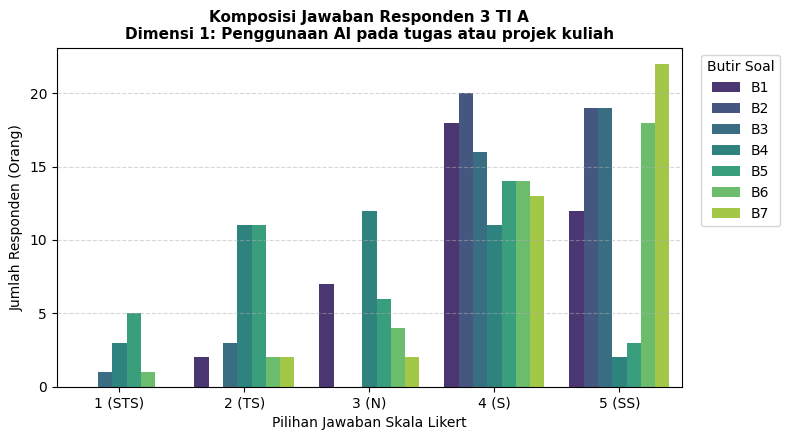

[TERSIMPAN] Gambar grafik 'Grafik_Dimensi_2.png' berhasil dibuat.


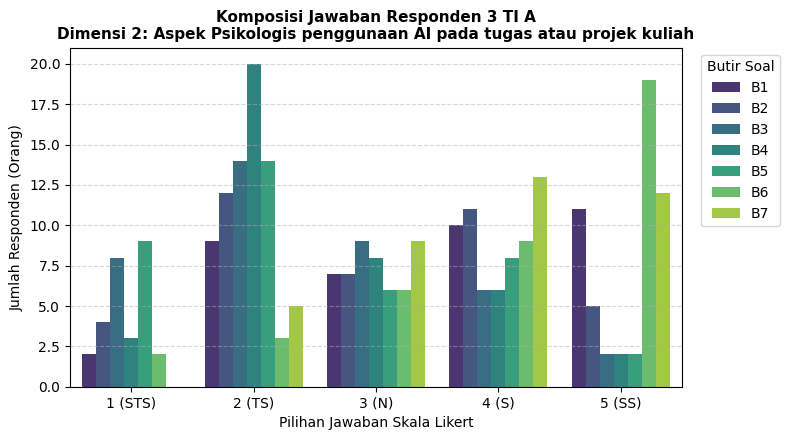

[TERSIMPAN] Gambar grafik 'Grafik_Dimensi_3.png' berhasil dibuat.


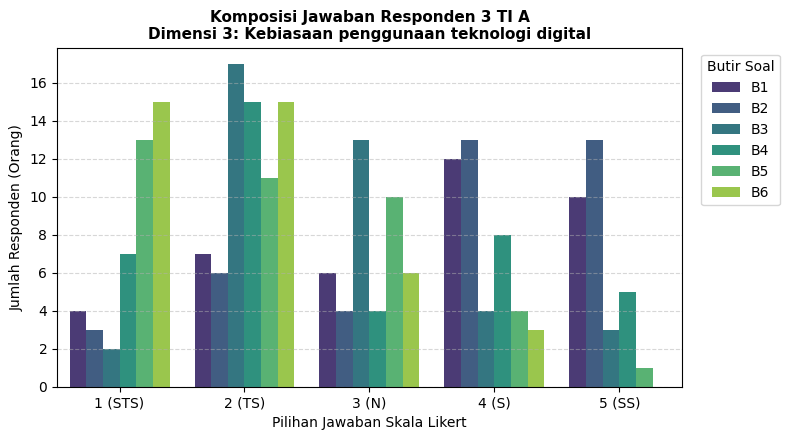

[TERSIMPAN] Gambar grafik 'Grafik_Dimensi_4.png' berhasil dibuat.


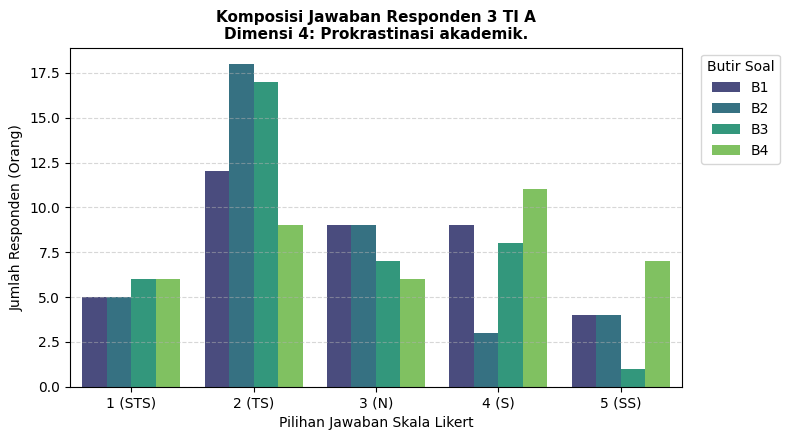

[TERSIMPAN] Gambar grafik 'Grafik_Dimensi_5.png' berhasil dibuat.


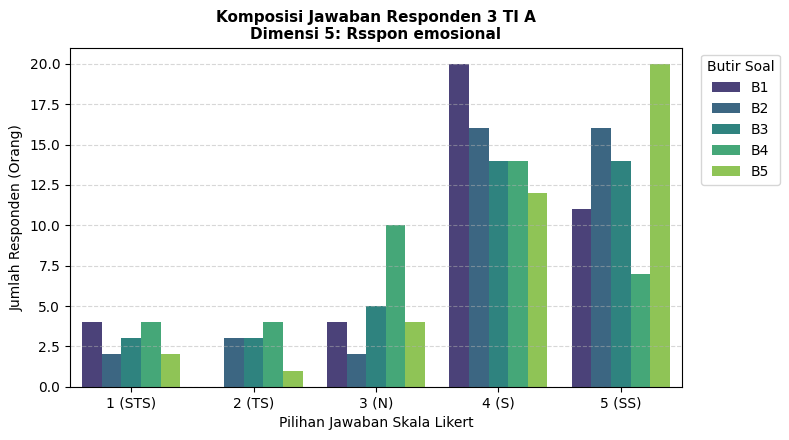


[SELESAI] Mengunduh file Excel 'Hasil_Uji_Validitas_Reliabilitas_3TIA.xlsx' sebagai lampiran laporan...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
print("=== TAHAP 4: VISUALISASI GRAFIK & SIMPAN DOKUMENTASI ===")

label_skala = {
    1: "1 (STS)",
    2: "2 (TS)",
    3: "3 (N)",
    4: "4 (S)",
    5: "5 (SS)"
}

for idx, (nama_dim, list_soal) in enumerate(daftar_dimensi.items(), 1):
    skor_dimensi = data_angka[list_soal].copy()
    # Ubah nama kolom menjadi B1, B2, dst. agar legenda grafik rapi
    skor_dimensi.columns = [f"B{i}" for i in range(1, len(list_soal) + 1)]

    # Ubah bentuk data untuk grafik
    data_grafik = skor_dimensi.melt(var_name="Kode Butir", value_name="Skor")
    data_grafik["Keterangan Jawaban"] = data_grafik["Skor"].map(label_skala)

    plt.figure(figsize=(8, 4.5))
    ax = sns.countplot(
        data=data_grafik,
        x="Keterangan Jawaban",
        hue="Kode Butir",
        order=["1 (STS)", "2 (TS)", "3 (N)", "4 (S)", "5 (SS)"],
        palette="viridis"
    )
    plt.title(f"Komposisi Jawaban Responden 3 TI A\nDimensi {idx}: {nama_dim}", fontsize=11, fontweight="bold")
    plt.xlabel("Pilihan Jawaban Skala Likert")
    plt.ylabel("Jumlah Responden (Orang)")
    plt.legend(title="Butir Soal", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.grid(axis="y", linestyle="--", alpha=0.5)
    plt.tight_layout()

    # Simpan otomatis sebagai gambar PNG
    nama_gambar = f"Grafik_Dimensi_{idx}.png"
    plt.savefig(nama_gambar, dpi=150)
    print(f"[TERSIMPAN] Gambar grafik '{nama_gambar}' berhasil dibuat.")
    plt.show()

# Simpan seluruh tabel hasil pengujian ke dalam satu file Excel (3 Sheet)
nama_excel_output = "Hasil_Uji_Validitas_Reliabilitas_3TIA.xlsx"
with pd.ExcelWriter(nama_excel_output) as writer:
    tabel_validitas_lengkap.to_excel(writer, sheet_name="Hasil_Validitas", index=False)
    df_reliabilitas.to_excel(writer, sheet_name="Hasil_Reliabilitas", index=False)
    df_deskriptif.to_excel(writer, sheet_name="Statistik_Deskriptif", index=False)

print(f"\n[SELESAI] Mengunduh file Excel '{nama_excel_output}' sebagai lampiran laporan...")
files.download(nama_excel_output)